In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

**Part B**

In [65]:
data = load_breast_cancer()
X = data.data
y = data.target

print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("Target names:", data.target_names)

Number of observations: 569
Number of features: 30
Number of classes: 2
Target names: ['malignant' 'benign']


Task 3.2

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training size: ", X_train.shape[0])
print("Test size: ", X_test.shape[0])

Training size:  455
Test size:  114


Task 4.1

In [67]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_train_pred = dt_model.predict(X_train)
dt_test_pred = dt_model.predict(X_test)

dt_train_acc = accuracy_score(y_train, dt_train_pred)
dt_test_acc = accuracy_score(y_test, dt_test_pred)

print("Training Accuracy:", dt_train_acc)
print("Test Accuracy:", dt_test_acc)

Training Accuracy: 1.0
Test Accuracy: 0.9122807017543859


Activity 5

In [68]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

rf_train_acc = accuracy_score(y_train, rf_train_pred)
rf_test_acc = accuracy_score(y_test, rf_test_pred)

print("Training Accuracy:", rf_train_acc)
print("Test Accuracy:", rf_test_acc)

Training Accuracy: 1.0
Test Accuracy: 0.956140350877193


Task 6.1

In [69]:
n_values = [1, 5, 10, 50, 100, 200]

rf_test_accuracies = []

for n in n_values:
    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)

    rf_test_accuracies.append(test_acc)

    print(n, test_acc)

1 0.9473684210526315
5 0.9385964912280702
10 0.9385964912280702
50 0.956140350877193
100 0.956140350877193
200 0.956140350877193


Task 6.2

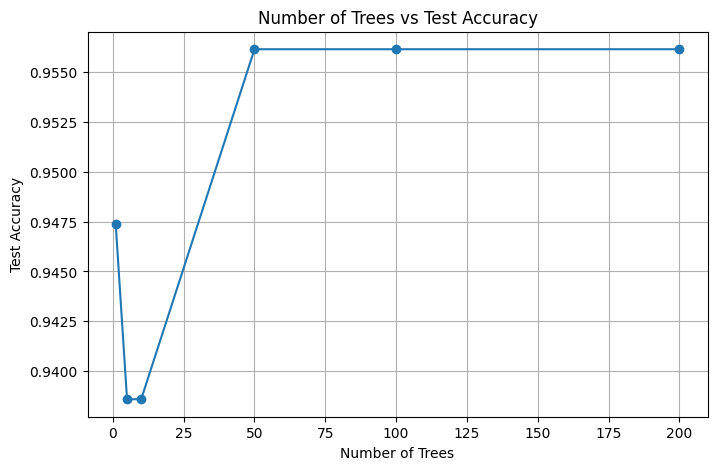

In [70]:
plt.figure(figsize=(8, 5))

plt.plot(
    n_values,
    rf_test_accuracies,
    marker='o'
)

plt.xlabel("Number of Trees")
plt.ylabel("Test Accuracy")
plt.title("Number of Trees vs Test Accuracy")
plt.grid(True)

plt.show()

Task 7.1

In [71]:
depth_values = [2, 4, 6, 10, None]

depth_train_acc = []
depth_test_acc = []

for depth in depth_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    depth_train_acc.append(train_acc)
    depth_test_acc.append(test_acc)

    print(depth, train_acc, test_acc)

2 0.9648351648351648 0.9473684210526315
4 0.9934065934065934 0.956140350877193
6 0.9956043956043956 0.9473684210526315
10 1.0 0.956140350877193
None 1.0 0.956140350877193


Task 7.2

In [72]:
feature_settings = ["sqrt", "log2", None]

for feature_setting in feature_settings:

    model = RandomForestClassifier(
        n_estimators=100,
        max_features=feature_setting,
        random_state=42
    )

    model.fit(X_train, y_train)

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    print(feature_setting, test_acc)

sqrt 0.956140350877193
log2 0.956140350877193
None 0.9385964912280702


Bonus — Feature Importance

worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
mean perimeter          0.069574
mean radius             0.068676
mean concavity          0.057638
mean area               0.049172
worst concavity         0.034340
dtype: float64


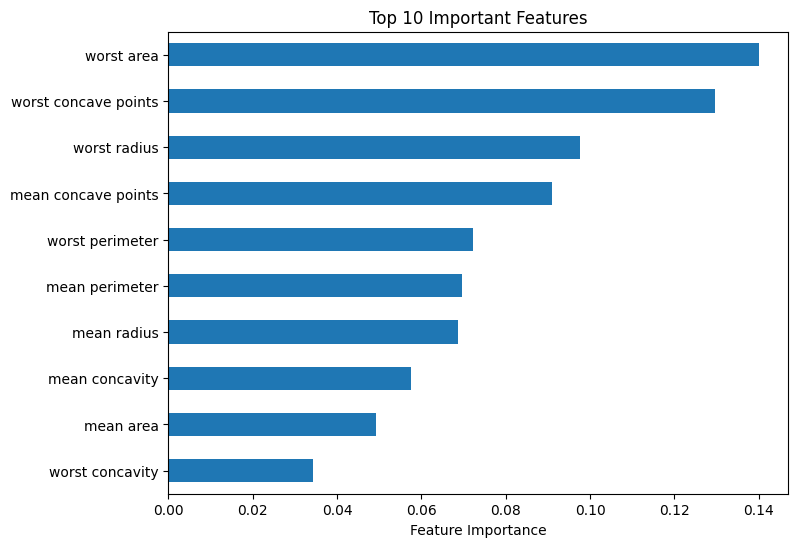

In [73]:
importances = pd.Series(
    rf_model.feature_importances_,
    index=data.feature_names
)

top10 = importances.sort_values(
    ascending=False
).head(10)

print(top10)

top10.sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features")
plt.show()

worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
mean perimeter          0.069574
mean radius             0.068676
mean concavity          0.057638
mean area               0.049172
worst concavity         0.034340
dtype: float64


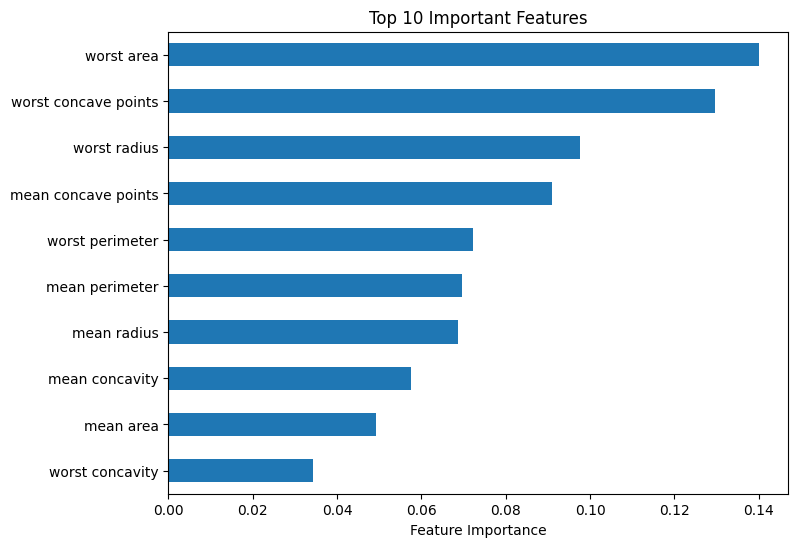

In [74]:
importances = pd.Series(
    rf_model.feature_importances_,
    index=data.feature_names
)

top10 = importances.sort_values(
    ascending=False
).head(10)

print(top10)

top10.sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features")
plt.show()

Part G

In [75]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_train_acc = accuracy_score(
    y_train,
    gb_model.predict(X_train)
)

gb_test_acc = accuracy_score(
    y_test,
    gb_model.predict(X_test)
)

print("Training Accuracy:", gb_train_acc)
print("Test Accuracy:", gb_test_acc)

Training Accuracy: 1.0
Test Accuracy: 0.956140350877193


Task 12.1

In [76]:
learning_rates = [0.01, 0.05, 0.10, 0.50, 1.00]

lr_train_acc = []
lr_test_acc = []

for lr in learning_rates:

    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=lr,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    lr_train_acc.append(train_acc)
    lr_test_acc.append(test_acc)

    print(lr, train_acc, test_acc)

0.01 0.9868131868131869 0.9210526315789473
0.05 1.0 0.9473684210526315
0.1 1.0 0.956140350877193
0.5 1.0 0.956140350877193
1.0 1.0 0.956140350877193


Task 12.2

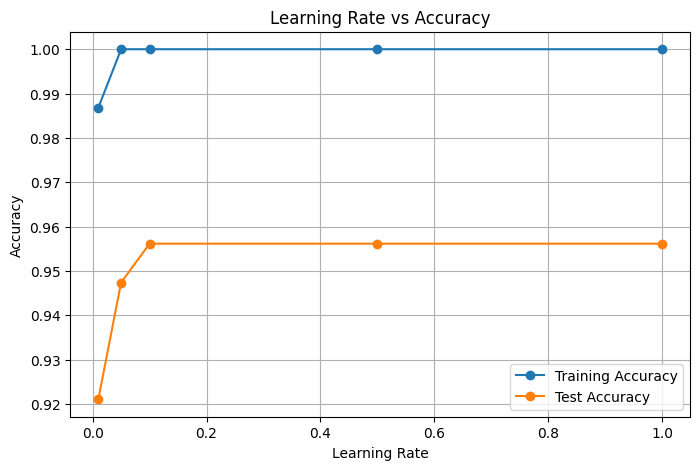

In [77]:
plt.figure(figsize=(8, 5))

plt.plot(
    learning_rates,
    lr_train_acc,
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    learning_rates,
    lr_test_acc,
    marker='o',
    label="Test Accuracy"
)

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Learning Rate vs Accuracy")
plt.legend()
plt.grid(True)

plt.show()

Part I

Activity 13

In [62]:
param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.10],
    "max_depth": [2, 3]
}

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

best_model = grid_search.best_estimator_

final_test_accuracy = accuracy_score(
    y_test,
    best_model.predict(X_test)
)

print("Final Test Accuracy:", final_test_accuracy)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
Best CV Accuracy: 0.9648351648351647
Final Test Accuracy: 0.9473684210526315


Challenge

In [78]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

random_params = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.5],
    "max_depth": [1, 2, 3, 4]
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=random_params,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    random_state=42
)

random_search.fit(X_train, y_train)

random_test_accuracy = accuracy_score(
    y_test,
    random_search.best_estimator_.predict(X_test)
)

print("Number of configurations evaluated:", 10)
print("Best Parameters:", random_search.best_params_)
print("Best CV Accuracy:", random_search.best_score_)
print("Final Test Accuracy:", random_test_accuracy)

Number of configurations evaluated: 10
Best Parameters: {'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.5}
Best CV Accuracy: 0.9692307692307693
Final Test Accuracy: 0.956140350877193
